In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import matplotlib.pyplot as plt

bucket = "insurance-pricing-model-akshayaa"
freq_train = pd.read_csv(f"s3://{bucket}/processed/train/freq_train.csv")
freq_test  = pd.read_csv(f"s3://{bucket}/processed/test/freq_test.csv")
print("Train:", freq_train.shape, "Test:", freq_test.shape)

def gini(actual, predicted, exposure):
    df = pd.DataFrame({'actual': actual, 'predicted': predicted, 'exposure': exposure})
    df = df.sort_values('predicted', ascending=True).reset_index(drop=True)
    df['cum_actual_pct'] = df['actual'].cumsum() / df['actual'].sum()
    df['cum_exposure_pct'] = df['exposure'].cumsum() / df['exposure'].sum()
    lorenz_area = np.trapezoid(df['cum_actual_pct'], df['cum_exposure_pct'])
    return 1 - 2 * lorenz_area

C:\Users\prish\OneDrive\Desktop\Insurance Project\Insurance-Underwriting-Pricing-Model\venv\lib\site-packages\fsspec\registry.py:305: UserWarning: Your installed version of s3fs is very old and known to cause
severe performance issues, see also https://github.com/dask/dask/issues/10276

To fix, you should specify a lower version bound on s3fs, or
update the current installation.

  warnings.warn(s3_msg)


Train: (541431, 38) Test: (135358, 38)


In [2]:
exclude_cols = ['IDpol', 'ClaimNb', 'Exposure']
feature_cols = [c for c in freq_train.columns if c not in exclude_cols]
print("Feature count:", len(feature_cols))

X_train = freq_train[feature_cols]
y_train = freq_train['ClaimNb']
base_margin_train = np.log(freq_train['Exposure'])

X_test = freq_test[feature_cols]
y_test = freq_test['ClaimNb']
base_margin_test = np.log(freq_test['Exposure'])

dtrain = xgb.DMatrix(X_train, label=y_train, base_margin=base_margin_train)
dtest  = xgb.DMatrix(X_test, label=y_test, base_margin=base_margin_test)

Feature count: 35


In [3]:
param_grid = [
    {"max_depth": 3, "eta": 0.1,  "num_round": 200},
    {"max_depth": 5, "eta": 0.1,  "num_round": 200},
    {"max_depth": 7, "eta": 0.1,  "num_round": 200},
    {"max_depth": 5, "eta": 0.05, "num_round": 400},
    {"max_depth": 5, "eta": 0.2,  "num_round": 100},
]

results = []
for combo in param_grid:
    params = {
        "objective": "count:poisson",
        "max_depth": combo["max_depth"],
        "eta": combo["eta"],
        "eval_metric": "poisson-nloglik",
    }
    booster = xgb.train(params, dtrain, num_boost_round=combo["num_round"])

    pred_train = booster.predict(dtrain) / freq_train['Exposure']
    pred_test  = booster.predict(dtest)  / freq_test['Exposure']

    gini_train = gini(freq_train['ClaimNb'], pred_train, freq_train['Exposure'])
    gini_test  = gini(freq_test['ClaimNb'], pred_test, freq_test['Exposure'])

    results.append({**combo, "gini_train": round(gini_train, 4), "gini_test": round(gini_test, 4)})
    print(combo, "-> train Gini:", round(gini_train, 4), " test Gini:", round(gini_test, 4))

results_df = pd.DataFrame(results)
results_df

{'max_depth': 3, 'eta': 0.1, 'num_round': 200} -> train Gini: 0.3271  test Gini: 0.3224
{'max_depth': 5, 'eta': 0.1, 'num_round': 200} -> train Gini: 0.3629  test Gini: 0.3365
{'max_depth': 7, 'eta': 0.1, 'num_round': 200} -> train Gini: 0.4165  test Gini: 0.3413
{'max_depth': 5, 'eta': 0.05, 'num_round': 400} -> train Gini: 0.3627  test Gini: 0.3362
{'max_depth': 5, 'eta': 0.2, 'num_round': 100} -> train Gini: 0.3616  test Gini: 0.3366


,max_depth,eta,num_round,gini_train,gini_test
0,3,0.10,200,0.3271,0.3224
1,5,0.10,200,0.3629,0.3365
2,7,0.10,200,0.4165,0.3413
3,5,0.05,400,0.3627,0.3362
4,5,0.20,100,0.3616,0.3366


### To handle time cost, the parameter values above were hardcoded. This technically is a grid search, but manually specified. If grid search was done using a real tool like GridSearchCV with max_depth ∈ {3,5,7,9}, eta ∈ {0.01,0.05,0.1,0.2}, and num_round ∈ {100,200,400,800}, this would give us 4×4×4 = 64 combinations that refits the model on 541k rows. Since this is being run in Docker locally in CPU, it would take a lot of time. To prevent diminishing returns i.e. instead of extracting the model with exhaustive tuning, we need to refer back to the business goal to compare Champion vs Challenger model and choose this step. However, if this was going into actual production pricing decisions, GridSearchCV could have been implemented. 

### Further, while comparing the model with different params: even though the one with depth=7 had highest test gini, the train-test gap is highest. This denotes overfitting. So, we choose the next best set of params (last one) where max_depth=5, eta=0.2, num_round=100. 

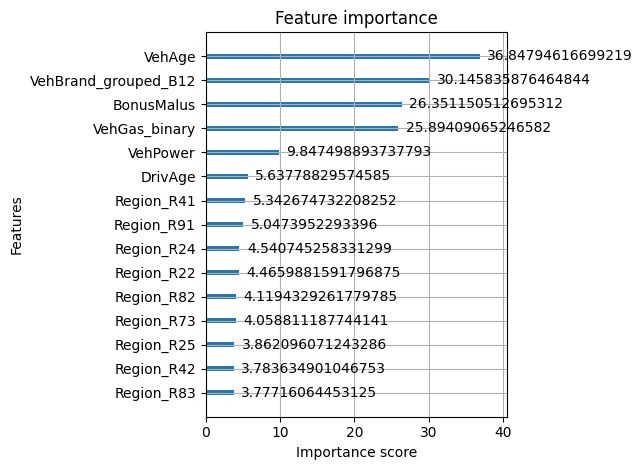

In [4]:
best_params = {"objective": "count:poisson", "max_depth": 5, "eta": 0.1, "eval_metric": "poisson-nloglik"}
best_num_round = 200

final_booster = xgb.train(best_params, dtrain, num_boost_round=best_num_round)

xgb.plot_importance(final_booster, max_num_features=15, importance_type='gain')
plt.tight_layout()
plt.show()